# A&E Waiting Times in England, 2019 to 2026
**Question:** How have A&E waiting times in England changed since 2019, and which regions are doing worst?
**Hypothesis:** Waiting times have got worse since 2019, and are worst in winter.
**Data:** NHS England Monthly A&E Time Series (Sept 2026) and the monthly provider CSV (Sept 2026).

In [1]:
!pip install xlrd


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\aksha\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
file = "Monthly-AE-Time-Series-September-2026-LS35fw.xls"
perf = pd.read_excel(file, sheet_name="Performance", header=13)
perf.head()

,Unnamed: 0,Period,Type 1 Departments - Major A&E,Type 2 Departments - Single Specialty,Type 3 Departments - Other A&E/Minor Injury Unit,Total Attendances < 4 hours,Type 1 Departments - Major A&E.1,Type 2 Departments - Single Specialty.1,Type 3 Departments - Other A&E/Minor Injury Unit.1,Total Attendances > 4 hours,Percentage in 4 hours or less (all),Percentage in 4 hours or less (type 1),Percentage in 4 hours or less (type 2),Percentage in 4 hours or less (type 3)
0,NaN,2010-11-01,1.065456e+06,53584.000000,485550.857143,1.604591e+06,45838.428571,143.428571,454.571429,46436.428571,0.971874,0.958752,0.997330,0.999065
1,NaN,2010-12-01,1.070729e+06,45395.857143,531699.428571,1.647824e+06,88475.285714,140.571429,1301.428571,89917.285714,0.948256,0.923676,0.996913,0.997558
2,NaN,2011-01-01,1.061898e+06,51420.571429,541588.857143,1.654907e+06,71982.571429,164.285714,742.428571,72889.285714,0.957814,0.936517,0.996815,0.998631
3,NaN,2011-02-01,1.007385e+06,51153.428571,493883.000000,1.552421e+06,46322.428571,95.857143,524.571429,46942.857143,0.970649,0.956039,0.998130,0.998939
4,NaN,2011-03-01,1.167090e+06,57694.857143,579483.571429,1.804268e+06,58132.142857,205.571429,835.000000,59172.714286,0.968245,0.952554,0.996450,0.998561


In [3]:
hosp = pd.read_csv("September-2026-CSV-Re72Eh.csv")
hosp.head()

,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
0,MSitAE-SEPTEMBER-2026,AJN,NHS ENGLAND NORTH EAST AND YORKSHIRE,WORKINGTON HEALTH LIMITED,0,0,492,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,MSitAE-SEPTEMBER-2026,NTV0B,NHS ENGLAND SOUTH EAST,ASHFORD WALK-IN-CENTRE,0,0,2584,0,0,0,...,273,0,0,0,0,0,0,0,0,0
2,MSitAE-SEPTEMBER-2026,NTV0W,NHS ENGLAND SOUTH EAST,WOKING WALK IN CENTRE,0,0,2773,0,0,0,...,84,0,0,0,0,0,0,0,0,0
3,MSitAE-SEPTEMBER-2026,RYY,NHS ENGLAND SOUTH EAST,KENT COMMUNITY HEALTH NHS FOUNDATION TRUST,0,0,6655,0,0,0,...,95,0,0,0,0,0,0,0,0,0
4,MSitAE-SEPTEMBER-2026,AAH,NHS ENGLAND SOUTH WEST,TETBURY HOSPITAL TRUST LTD,0,0,702,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
hosp = pd.read_csv("September-2026-CSV-Re72Eh.csv")

In [5]:
perf.columns

Index(['Unnamed: 0', 'Period', 'Type 1 Departments - Major A&E',
       'Type 2 Departments - Single Specialty',
       'Type 3 Departments - Other A&E/Minor Injury Unit',
       'Total Attendances < 4 hours', 'Type 1 Departments - Major A&E.1',
       'Type 2 Departments - Single Specialty.1',
       'Type 3 Departments - Other A&E/Minor Injury Unit.1',
       'Total Attendances > 4 hours', 'Percentage in 4 hours or less (all)',
       'Percentage in 4 hours or less (type 1)',
       'Percentage in 4 hours or less (type 2)',
       'Percentage in 4 hours or less (type 3)'],
      dtype='str')

## Step 1: Cleaning
Removed an empty column, converted dates, kept 2019 onwards, and turned the fractions into percentages.
Result: 93 rows, no missing values.

In [6]:
perf = perf.drop(columns=perf.columns[0]) # remove the empty first column

In [7]:
perf.columns

Index(['Period', 'Type 1 Departments - Major A&E',
       'Type 2 Departments - Single Specialty',
       'Type 3 Departments - Other A&E/Minor Injury Unit',
       'Total Attendances < 4 hours', 'Type 1 Departments - Major A&E.1',
       'Type 2 Departments - Single Specialty.1',
       'Type 3 Departments - Other A&E/Minor Injury Unit.1',
       'Total Attendances > 4 hours', 'Percentage in 4 hours or less (all)',
       'Percentage in 4 hours or less (type 1)',
       'Percentage in 4 hours or less (type 2)',
       'Percentage in 4 hours or less (type 3)'],
      dtype='str')

In [8]:
perf["Period"] = pd.to_datetime(perf["Period"]) # make sure Period is a proper date

In [9]:
perf["Period"].dtype

dtype('<M8[us]')

In [10]:
ts = perf[["Period",
           "Percentage in 4 hours or less (all)",
           "Percentage in 4 hours or less (type 1)"]].copy() # keep only the columns we need

In [11]:
ts.head()

,Period,Percentage in 4 hours or less (all),Percentage in 4 hours or less (type 1)
0,2010-11-01,0.971874,0.958752
1,2010-12-01,0.948256,0.923676
2,2011-01-01,0.957814,0.936517
3,2011-02-01,0.970649,0.956039
4,2011-03-01,0.968245,0.952554


In [12]:
ts.columns = ["month", "pct_all", "pct_type1"] # give them short names

In [13]:
ts.head()

,month,pct_all,pct_type1
0,2010-11-01,0.971874,0.958752
1,2010-12-01,0.948256,0.923676
2,2011-01-01,0.957814,0.936517
3,2011-02-01,0.970649,0.956039
4,2011-03-01,0.968245,0.952554


In [14]:
ts = perf[["Period",
           "Percentage in 4 hours or less (all)",
           "Percentage in 4 hours or less (type 1)"]].copy()

ts.columns = ["month", "pct_all", "pct_type1"]

In [15]:
ts.head()

,month,pct_all,pct_type1
0,2010-11-01,0.971874,0.958752
1,2010-12-01,0.948256,0.923676
2,2011-01-01,0.957814,0.936517
3,2011-02-01,0.970649,0.956039
4,2011-03-01,0.968245,0.952554


In [16]:
ts["pct_all"] = ts["pct_all"] * 100
ts["pct_type1"] = ts["pct_type1"] * 100 # turn 0.74 into 74 (percentages are easier to read)

In [17]:
ts.head()

,month,pct_all,pct_type1
0,2010-11-01,97.187422,95.875222
1,2010-12-01,94.825623,92.367582
2,2011-01-01,95.781374,93.651662
3,2011-02-01,97.064905,95.603861
4,2011-03-01,96.824546,95.255379


In [18]:
ts = ts[ts["month"] >= "2019-01-01"] # keep 2019 onwards, as in your question

In [19]:
ts.head()

,month,pct_all,pct_type1
98,2019-01-01,84.352514,76.064489
99,2019-02-01,84.225250,75.757821
100,2019-03-01,86.609312,79.494210
101,2019-04-01,85.125168,77.140420
102,2019-05-01,86.631069,79.081330


print(ts.shape)
print(ts.isna().sum())

In [20]:
!pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\aksha\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [21]:
import matplotlib.pyplot as plt

## Step 2: Trend over time
Performance fell sharply in 2021 to 2022 and has stayed flat at a low level since.
Note: May 2020 is the best month because of COVID lockdown (fewer patients), not better care.

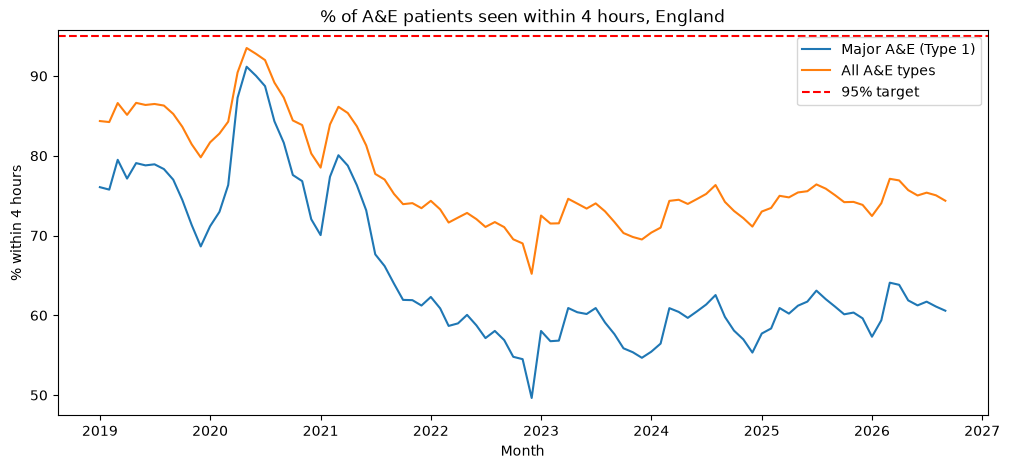

In [22]:
#Draw a chart
plt.figure(figsize=(12, 5))

plt.plot(ts["month"], ts["pct_type1"], label="Major A&E (Type 1)")
plt.plot(ts["month"], ts["pct_all"], label="All A&E types")

plt.axhline(95, color="red", linestyle="--", label="95% target")

plt.title("% of A&E patients seen within 4 hours, England")
plt.ylabel("% within 4 hours")
plt.xlabel("Month")

plt.legend()

plt.show()

In [23]:
#Find the best and worst months
print("Worst month (all types):")
print(ts.loc[ts["pct_all"].idxmin()])
print()
print("Best month (all types):")
print(ts.loc[ts["pct_all"].idxmax()])

Worst month (all types):
month        2022-12-01 00:00:00
pct_all                65.202721
pct_type1              49.636835
Name: 145, dtype: object

Best month (all types):
month        2020-05-01 00:00:00
pct_all                93.508724
pct_type1              91.158505
Name: 114, dtype: object


## Data limitations
- May 2019 to May 2023: 4-hour figures exclude 14 trusts testing new targets.
- Aug 2022 to Feb 2023: a cyber-attack made Type 3 figures too low, so Type 1 is more reliable for this period.
- 2026 has only 9 months.

In [24]:
ts["year"] = ts["month"].dt.year

In [25]:
ts.head()

,month,pct_all,pct_type1,year
98,2019-01-01,84.352514,76.064489,2019
99,2019-02-01,84.225250,75.757821,2019
100,2019-03-01,86.609312,79.494210,2019
101,2019-04-01,85.125168,77.140420,2019
102,2019-05-01,86.631069,79.081330,2019


In [26]:
yearly = ts.groupby("year")[["pct_all", "pct_type1"]].mean().round(1)

In [27]:
yearly

,pct_all,pct_type1
year,,
2019,84.7,76.3
2020,86.9,80.8
2021,79.2,69.9
2022,71.2,57.6
2023,72.2,58.1
2024,73.4,59.0
2025,74.7,60.5
2026,75.1,61.2


In [28]:
# use 2022 onwards, so COVID lockdown months don't distort the pattern
recent = ts[ts["month"] >= "2022-01-01"].copy()
by_month = recent.groupby(recent["month"].dt.month)[["pct_all", "pct_type1"]].mean().round(1)

In [29]:
by_month

,pct_all,pct_type1
month,,
1,72.5,58.2
2,72.7,58.4
3,73.9,60.3
4,74.6,60.9
5,74.4,60.6
6,74.1,60.5
7,74.4,60.8
8,74.4,60.6
9,73.3,59.2


In [30]:
by_month.index.name = "calendar_month"
by_month

,pct_all,pct_type1
calendar_month,,
1,72.5,58.2
2,72.7,58.4
3,73.9,60.3
4,74.6,60.9
5,74.4,60.6
6,74.1,60.5
7,74.4,60.8
8,74.4,60.6
9,73.3,59.2


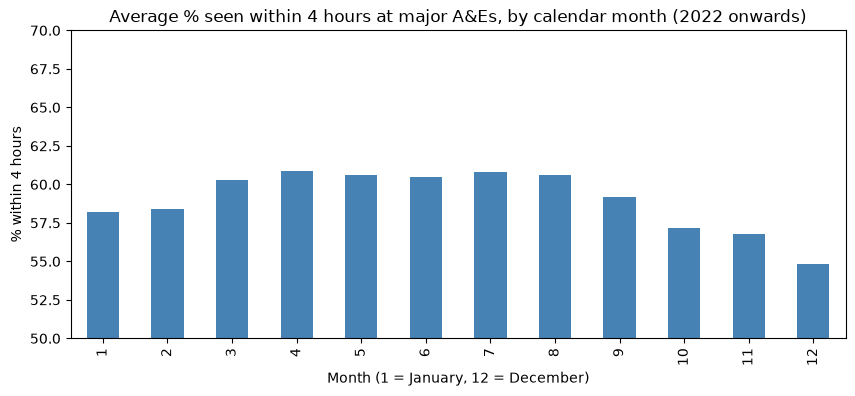

In [31]:
#Bar chart of Cell 2
by_month["pct_type1"].plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Average % seen within 4 hours at major A&Es, by calendar month (2022 onwards)")
plt.xlabel("Month (1 = January, 12 = December)")
plt.ylabel("% within 4 hours")
plt.ylim(50, 70)
plt.savefig("avg_4h.png", dpi=150, bbox_inches="tight")
plt.show()

## Finding: trend and seasonality

- Major A&E performance fell sharply in 2021 to 2022 (low of 57.6%) and has recovered only slightly since (61.2% in 2026).
- Performance is worst in winter: about 55% in December vs about 61% in April.
- Hypothesis result: partly supported (big drop, not a steady decline); winter pattern supported.
- Caveat: 2026 has only 9 months; each calendar month has 4 to 5 years of data.

In [32]:
#Calculate % within 4 hours by region
# remove the TOTAL row so we don't double count
hosp_clean = hosp[hosp["Parent Org"]!="TOTAL"].copy()

In [33]:
att = "A&E attendances Type 1"
over = "Attendances over 4hrs Type 1"

In [34]:
reg=hosp_clean.groupby("Parent Org")[[att,over]].sum()

In [35]:
reg.head()

,A&E attendances Type 1,Attendances over 4hrs Type 1
Parent Org,,
NHS ENGLAND EAST OF ENGLAND,161737,61813
NHS ENGLAND LONDON,245106,91582
NHS ENGLAND MIDLANDS,276429,114356
NHS ENGLAND NORTH EAST AND YORKSHIRE,231373,89487
NHS ENGLAND NORTH WEST,207342,88759


In [36]:
reg

,A&E attendances Type 1,Attendances over 4hrs Type 1
Parent Org,,
NHS ENGLAND EAST OF ENGLAND,161737,61813
NHS ENGLAND LONDON,245106,91582
NHS ENGLAND MIDLANDS,276429,114356
NHS ENGLAND NORTH EAST AND YORKSHIRE,231373,89487
NHS ENGLAND NORTH WEST,207342,88759
NHS ENGLAND SOUTH EAST,219592,81465
NHS ENGLAND SOUTH WEST,133861,57168


In [37]:
hosp_clean["Parent Org"].tail()

186    NHS ENGLAND NORTH WEST 
187    NHS ENGLAND NORTH WEST 
188    NHS ENGLAND SOUTH EAST 
189    NHS ENGLAND SOUTH EAST 
190      NHS ENGLAND MIDLANDS 
Name: Parent Org, dtype: str

In [38]:
hosp_clean = hosp[hosp["Parent Org"] != "TOTAL"].copy()

hosp_clean.tail()

,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
186,MSitAE-SEPTEMBER-2026,RXN,NHS ENGLAND NORTH WEST,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,12803,0,3316,227,0,69,...,236,33,0,1,863,425,3463,0,96,1283
187,MSitAE-SEPTEMBER-2026,RBL,NHS ENGLAND NORTH WEST,WIRRAL UNIVERSITY TEACHING HOSPITAL NHS FOUNDA...,7917,0,2517,129,0,106,...,397,63,0,19,480,498,2321,0,0,1702
188,MSitAE-SEPTEMBER-2026,RN7,NHS ENGLAND SOUTH EAST,DARTFORD AND GRAVESHAM NHS TRUST,12375,0,4121,0,0,0,...,98,0,0,0,413,490,3815,0,0,314
189,MSitAE-SEPTEMBER-2026,RTH,NHS ENGLAND SOUTH EAST,OXFORD UNIVERSITY HOSPITALS NHS FOUNDATION TRUST,13610,1472,2856,2055,0,0,...,0,361,0,0,298,8,5677,117,0,4224
190,MSitAE-SEPTEMBER-2026,RWD,NHS ENGLAND MIDLANDS,UNITED LINCOLNSHIRE TEACHING HOSPITALS NHS TRUST,17584,0,4440,0,0,0,...,485,0,0,0,628,1347,4773,0,0,1211


In [39]:
reg["pct_within_4h"] = (1 - reg[over] / reg[att]) * 100

In [40]:
reg.head()

,A&E attendances Type 1,Attendances over 4hrs Type 1,pct_within_4h
Parent Org,,,
NHS ENGLAND EAST OF ENGLAND,161737,61813,61.781782
NHS ENGLAND LONDON,245106,91582,62.635758
NHS ENGLAND MIDLANDS,276429,114356,58.630969
NHS ENGLAND NORTH EAST AND YORKSHIRE,231373,89487,61.323491
NHS ENGLAND NORTH WEST,207342,88759,57.191982


In [41]:
# tidy the names and sort worst to best
reg.index=reg.index.str.replace("NHS ENGLAND ", "", regex=False).str.title()

In [42]:
reg

,A&E attendances Type 1,Attendances over 4hrs Type 1,pct_within_4h
Parent Org,,,
East Of England,161737,61813,61.781782
London,245106,91582,62.635758
Midlands,276429,114356,58.630969
North East And Yorkshire,231373,89487,61.323491
North West,207342,88759,57.191982
South East,219592,81465,62.901654
South West,133861,57168,57.293013


In [43]:
reg=reg.sort_values("pct_within_4h")
reg.round(1)

,A&E attendances Type 1,Attendances over 4hrs Type 1,pct_within_4h
Parent Org,,,
North West,207342,88759,57.2
South West,133861,57168,57.3
Midlands,276429,114356,58.6
North East And Yorkshire,231373,89487,61.3
East Of England,161737,61813,61.8
London,245106,91582,62.6
South East,219592,81465,62.9


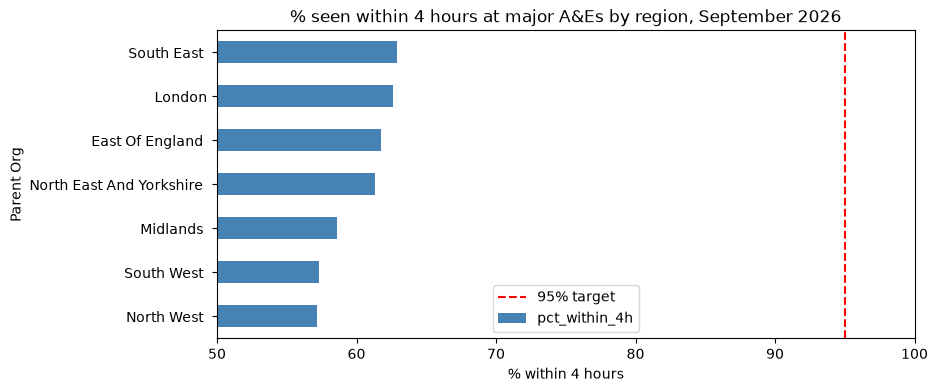

In [44]:
reg["pct_within_4h"].plot(kind="barh", figsize=(9, 4), color="steelblue")
plt.axvline(95, color="red", linestyle="--", label="95% target")
plt.title("% seen within 4 hours at major A&Es by region, September 2026")
plt.xlabel("% within 4 hours")
plt.xlim(50, 100)
plt.legend()
plt.savefig("regions_4h.png", dpi=150, bbox_inches="tight")
plt.show()

In [45]:
#The 10 worst hospital trusts
trusts = hosp_clean[hosp_clean[att] > 1000].copy()   # only real major A&Es
trusts["pct_within_4h"] = (1 - trusts[over] / trusts[att]) * 100

trusts[["Org name", "Parent Org", att, "pct_within_4h"]] \
    .sort_values("pct_within_4h").head(10).round(1)

,Org name,Parent Org,A&E attendances Type 1,pct_within_4h
103,UNIVERSITY HOSPITALS PLYMOUTH NHS TRUST,NHS ENGLAND SOUTH WEST,9089,36.2
113,NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST,NHS ENGLAND NORTH EAST AND YORKSHIRE,5103,40.1
88,KINGSTON AND RICHMOND NHS FOUNDATION TRUST,NHS ENGLAND LONDON,7544,41.5
155,HULL UNIVERSITY TEACHING HOSPITALS NHS TRUST,NHS ENGLAND NORTH EAST AND YORKSHIRE,10218,42.4
121,THE SHREWSBURY AND TELFORD HOSPITAL NHS TRUST,NHS ENGLAND MIDLANDS,11747,43.2
187,WIRRAL UNIVERSITY TEACHING HOSPITAL NHS FOUNDA...,NHS ENGLAND NORTH WEST,7917,43.3
178,"WRIGHTINGTON, WIGAN AND LEIGH TEACHING HOSPITA...",NHS ENGLAND NORTH WEST,7034,43.4
143,LEWISHAM AND GREENWICH NHS TRUST,NHS ENGLAND LONDON,16492,44.1
161,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,NHS ENGLAND MIDLANDS,13656,44.6
101,UNIVERSITY HOSPITALS OF NORTH MIDLANDS NHS TRUST,NHS ENGLAND MIDLANDS,15160,45.3


## Finding: regions and trusts (Sept 2026 snapshot)
- Worst regions at major A&Es: North West (57.2%) and South West (57.3%); best: South East (62.9%).
- Regions differ by only about 6 points; all are 32+ points below the 95% target.
- No simple north/south pattern. Differences between trusts (36% to 45% in the worst 10) are larger than between regions.
- Data cleaning: removed the TOTAL row (double counting) and trimmed trailing spaces in Parent Org.
- Caveat: one month only.

In [46]:
#The dangerous waits, 12 hours or more
twelve=("Patients who have waited 12+ hrs from DTA to admission")

reg12=hosp_clean.groupby("Parent Org")[[att,twelve]].sum()
reg12.index=reg12.index.str.replace("NHS ENGLAND","",regex=False).str.title()
# 12-hour waits per 1,000 major A&E attendances
reg12["waits_12h_per_1000"]=reg12[twelve]/reg12[att]*1000
reg12=reg12.sort_values("waits_12h_per_1000", ascending=False)
reg12.round(1)

,A&E attendances Type 1,Patients who have waited 12+ hrs from DTA to admission,waits_12h_per_1000
Parent Org,,,
North West,207342,9970,48.1
Midlands,276429,12623,45.7
London,245106,8713,35.5
South East,219592,6776,30.9
East Of England,161737,4728,29.2
South West,133861,3888,29.0
North East And Yorkshire,231373,3884,16.8


## Finding: 12-hour waits by region (Sept 2026)
- North West has the highest rate of 12-hour waits (48.1 per 1,000 major A&E attendances), followed by Midlands (45.7). North East and Yorkshire has the lowest (16.8).
- The 4-hour and 12-hour measures do not always agree (e.g. South West is 2nd worst on 4 hours but 6th on 12-hour waits).
- Caveat: 12-hour waits are counted from decision to admit, not arrival; rate is per Type 1 attendance (approximation); one month only.

In [47]:
reg.index = reg.index.str.strip()
reg12.index = reg12.index.str.strip()

# combine the two regional measures into one table
regions = reg[["pct_within_4h"]].join(reg12[["waits_12h_per_1000"]]).reset_index()

# save clean files into your AE_Project folder
ts.to_csv("clean_time_series.csv", index=False)
by_month.reset_index().to_csv("clean_by_month.csv", index=False)
regions.to_csv("clean_regions.csv", index=False)
trusts.to_csv("clean_trusts.csv", index=False)

regions.round(1)

,Parent Org,pct_within_4h,waits_12h_per_1000
0,North West,57.2,48.1
1,South West,57.3,29.0
2,Midlands,58.6,45.7
3,North East And Yorkshire,61.3,16.8
4,East Of England,61.8,29.2
5,London,62.6,35.5
6,South East,62.9,30.9
